# 05. Feature engineering: the hidden information (Task 5)

**Questions this notebook serves.** Q1 (which flights will leave more than 15 minutes late or be cancelled, warned two hours before departure) and Q3 (which flights will be cancelled). The models of Task 6 can only be as good as the columns we give them, so here we build about 50 columns from five sources: the calendar, the flight, the plane, the weather and what is happening at the airport *right now*.

**The time contract (decision D2).** Every feature is computed as of **T = scheduled departure minus 2 hours**. Anything that is only known after T is never a feature. Three ideas make this checkable:
1. Actual departure time of a flight = scheduled time + `dep_delay` minutes. A previous event can be used only if its actual time is at or before T.
2. Schedules (which flights are planned) are known long in advance, so counting scheduled flights is allowed.
3. Weather: the TASKS sheet asks for the weather of the scheduled hour. That is a stand-in for a *forecast* and is the one declared exception to the rule (D5). A second, strict set uses only observations at or before T.

**Outputs.** `data/processed/features.parquet` (435,352 rows), `feature_table.parquet`, `features_weather_literal.parquet` (the literal-join weather, only for the Task 6 comparison row).

**Reminder of the split rules (T9).** Anything with a fitted value (target statistics, the carrier-level plane imputation, the manufacturer grouping) is fitted on January to September only.

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from zoneinfo import ZoneInfo
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from utils import *

warnings.filterwarnings("ignore")
set_seed()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

fl = pd.read_parquet(PROC / "flights_clean.parquet")
we = pd.read_parquet(PROC / "weather_clean.parquet")
pl = pd.read_parquet(PROC / "planes_clean.parquet")
ap = pd.read_parquet(PROC / "airports_clean.parquet")
gr = pd.read_parquet(PROC / "groups_airport.parquet")

df = fl.sort_values("flight_row_id").reset_index(drop=True)
assert len(df) == 435_352 and df.flight_row_id.is_unique
EPOCH = pd.Timestamp("2023-01-01")
sched_utc = df.sched_dt.dt.tz_convert("UTC").dt.tz_localize(None)
df["sched_min"] = (sched_utc - EPOCH).dt.total_seconds() / 60          # scheduled departure, minutes since 1 Jan 2023 UTC
df["T_min"] = df.sched_min - 120                                        # the prediction moment T
df["actual_min"] = df.sched_min + df.dep_delay.astype(float)            # actual departure (NaN if cancelled)
df["date"] = df.sched_dt.dt.tz_localize(None).dt.normalize()            # scheduled local date
df["part"] = np.where(df.month.isin(TRAIN_MONTHS), "train", "test")
df["val"] = df.month.isin(VAL_MONTHS)
TRAIN = (df.part == "train").to_numpy()
assert TRAIN.sum() == 330_883 and (~TRAIN).sum() == 104_469 and df.val.sum() == 108_481
print("rows:", len(df), "| train", TRAIN.sum(), "| test", (~TRAIN).sum(), "| validation (inside train)", df.val.sum())
print("earliest actual departure relative to its own T (minutes, must stay above 0):", round((df.actual_min - df.T_min).min(), 1))

rows: 435352 | train 330883 | test 104469 | validation (inside train) 108481
earliest actual departure relative to its own T (minutes, must stay above 0): 70.0


The last line is the key to everything below: the earliest a flight ever leaves is 50 minutes before its schedule, so a flight scheduled *after* flight *f* can never have left before *f*'s time T (which is 2 hours before *f*'s schedule). That is why "events with actual departure at or before T" are always real information from the past.

## 1. Calendar features

From the scheduled local time. `is_holiday_period` = the flight's date is one of the 2023 US federal holidays or one of the 3 days before it. The list is written out below; source: US Office of Personnel Management, "Federal holidays 2023" (https://www.opm.gov/policy-data-oversight/pay-leave/federal-holidays/). Where a holiday fell on a weekend the observed date is used (1 January was a Sunday, observed Monday 2 January; 11 November was a Saturday, observed Friday 10 November).

In [2]:
HOLIDAYS_2023 = {"New Year's Day (observed)": "2023-01-02", "Martin Luther King Jr. Day": "2023-01-16", "Presidents Day": "2023-02-20",
                 "Memorial Day": "2023-05-29", "Juneteenth": "2023-06-19", "Independence Day": "2023-07-04", "Labor Day": "2023-09-04",
                 "Columbus Day": "2023-10-09", "Veterans Day (observed)": "2023-11-10", "Thanksgiving": "2023-11-23", "Christmas": "2023-12-25"}
hol = pd.to_datetime(list(HOLIDAYS_2023.values()))
in_window = np.zeros(len(df), bool)
for h in hol:
    in_window |= ((df.date >= h - pd.Timedelta(days=3)) & (df.date <= h)).to_numpy()

F = pd.DataFrame({"flight_row_id": df.flight_row_id})
F["dow"] = df.sched_dt.dt.dayofweek.astype(int)
F["month"] = df.month.astype(int)
F["hour"] = df.hour.astype(int)
F["minute_of_day"] = (df.hour.astype(int) * 60 + df.minute.astype(int))
F["hour_sin"] = np.sin(2 * np.pi * F.minute_of_day / 1440)
F["hour_cos"] = np.cos(2 * np.pi * F.minute_of_day / 1440)
F["is_weekend"] = (F.dow >= 5).astype(int)
F["week_of_year"] = df.sched_dt.dt.isocalendar().week.astype(int).to_numpy()
F["is_holiday_period"] = in_window.astype(int)
print(f"{F.is_holiday_period.mean()*100:.1f}% of flights are in a holiday period (11 holidays x 4 days)")
display(F.head(3))

10.8% of flights are in a holiday period (11 holidays x 4 days)


,flight_row_id,dow,month,hour,minute_of_day,hour_sin,hour_cos,is_weekend,week_of_year,is_holiday_period
0,0,6,1,20,1238,-0.771625,0.636078,1,52,1
1,1,6,1,23,1380,-0.258819,0.965926,1,52,1
2,2,6,1,23,1424,-0.069756,0.997564,1,52,1


## 2. Flight and route features

`distance` is known in advance. `sched_block_min` is the scheduled flying time in minutes: the scheduled arrival (destination local time, `sched_arr_time`) converted to UTC with the destination's time zone from `airports.csv`, minus the scheduled departure in UTC. The plan asks us to **verify it and drop it if it cannot be validated**, so the checks come first: it must be positive, must track the distance, and must be close to the real `air_time` plus a taxi allowance. (`air_time` is used here only for this check, never as a feature.)

In [3]:
dest_tz = ap.set_index("faa").tzone
arr_naive = df.date + pd.to_timedelta((df.sched_arr_time // 100) * 60 + df.sched_arr_time % 100, unit="min")
arr_utc = pd.Series(pd.NaT, index=df.index, dtype="datetime64[us]")
nat_count = 0
for tzname, idx in df.groupby(df.dest.map(dest_tz)).groups.items():
    loc = arr_naive.loc[idx].dt.tz_localize(ZoneInfo(tzname), ambiguous="NaT", nonexistent="NaT")
    nat_count += int(loc.isna().sum())
    arr_utc.loc[idx] = loc.dt.tz_convert("UTC").dt.tz_localize(None)
dep_utc = sched_utc
block = ((arr_utc - dep_utc).dt.total_seconds() / 60) % 1440          # a flight never lasts a day: wrap around midnight
print("arrival times that fall in a repeated or missing DST hour (set to NaN):", nat_count)
ok = block.notna()
print("block minutes: min", round(block.min()), "| median", round(block.median()), "| max", round(block.max()))
c1 = np.corrcoef(block[ok], df.distance[ok].astype(float))[0, 1]
gap = (block - df.air_time.astype(float)).dropna()
spd = df.distance.astype(float) / (block / 60)
print(f"correlation of block time with distance: {c1:.3f}")
print(f"block minus real air_time (minutes): median {gap.median():.0f}, 5th percentile {gap.quantile(.05):.0f}, 95th percentile {gap.quantile(.95):.0f}")
print(f"implied speed distance/block (mph): median {spd.median():.0f}, 1st percentile {spd.quantile(.01):.0f}, 99th percentile {spd.quantile(.99):.0f}")
VALID_BLOCK = (c1 > 0.95) and (block.dropna() > 0).all() and 200 < spd.median() < 600 and 0 < gap.median() < 60
print("sched_block_min validated:", VALID_BLOCK)

arrival times that fall in a repeated or missing DST hour (set to NaN): 7
block minutes: min 14 | median 163 | max 1435
correlation of block time with distance: 0.993
block minus real air_time (minutes): median 42, 5th percentile 22, 95th percentile 63
implied speed distance/block (mph): median 298, 1st percentile 119, 99th percentile 418
sched_block_min validated: True


In [4]:
F["distance"] = df.distance.astype(int)
if VALID_BLOCK:
    F["sched_block_min"] = block.round().astype("Int64").astype(float)
F["carrier"] = df.carrier
F["origin"] = df.origin
F["dest"] = df.dest
F["route"] = df.origin + "-" + df.dest
F["dest_group"] = df.dest.map(gr.set_index("dest").dest_group)
assert F.dest_group.notna().all()
print(F.dest_group.value_counts().to_dict())
print("missing sched_block_min:", int(F.sched_block_min.isna().sum()) if "sched_block_min" in F else "dropped")

{'G2': 300475, 'G1': 131450, 'G3': 2982, 'small': 445}
missing sched_block_min: 7


## 3. Plane features and the missing-tail trap (decision D10)

`planes.csv` gives age, seats, manufacturer and engines by `tailnum`. Two traps (T2, found in Tasks 1 and 2):
- Some cancelled flights have **no tail number**, so missing aircraft data can reveal the outcome; the agency cannot know it at T.
- 277 tails used by flights are not in `planes.csv` (9,371 flights), a data gap unrelated to cancellation.

**Rule (D10).** For missing or unmatched tails, fill each numeric plane feature with the carrier's Jan-Sep training median and each categorical feature with its carrier's Jan-Sep training mode. Fit these statistics using flights with a known aircraft only; use the corresponding Jan-Sep global median or mode when a carrier has no usable training aircraft. Apply the same training-only rule to missing aircraft years. Do not add a missing-value flag. The ablation below checks that plane features no longer reveal the missing-tail pattern.

In [5]:
real = df.tailnum.notna() & df.tailnum.isin(pl.tailnum)
need_fill = ~real
print(f"flights with a real, known aircraft: {real.sum():,}; to fill: {need_fill.sum():,} (missing tail {df.tailnum.isna().sum():,}; tail not in planes.csv {(df.tailnum.notna() & ~real).sum():,})")

P = pl.set_index("tailnum")
plane = pd.DataFrame(index=df.index)
plane["plane_age"] = (2023 - df.tailnum.map(P.year)).astype(float)
plane["seats"] = df.tailnum.map(P.seats).astype(float)
plane["engines"] = df.tailnum.map(P.engines).astype(float)
manu = df.tailnum.map(P.manufacturer)
train_known = real.to_numpy() & TRAIN
top_manu = manu[train_known].value_counts().head(6).index
plane["manufacturer"] = manu.where(manu.isin(top_manu), "OTHER")
plane.loc[manu.isna(), "manufacturer"] = np.nan

numeric_plane = ["plane_age", "seats", "engines"]
F[numeric_plane] = plane[numeric_plane]
F["manufacturer"] = plane["manufacturer"]
train_plane = F.loc[train_known]
train_carriers = df.loc[train_known, "carrier"]
carrier_medians = train_plane.groupby(train_carriers)[numeric_plane].median()
global_medians = train_plane[numeric_plane].median()
for col in numeric_plane:
    fills = df.carrier.map(carrier_medians[col]).fillna(global_medians[col])
    F[col] = F[col].fillna(fills)

carrier_modes = train_plane.groupby(train_carriers).manufacturer.agg(lambda s: s.mode().iloc[0])
global_mode = train_plane.manufacturer.mode().iloc[0]
manufacturer_fills = df.carrier.map(carrier_modes).fillna(global_mode)
F["manufacturer"] = F.manufacturer.fillna(manufacturer_fills)
assert F[[*numeric_plane, "manufacturer"]].notna().all().all()
print(f"missing or unmatched tails filled from carrier Jan-Sep statistics: {int(need_fill.sum()):,}")
print("carriers without a known Jan-Sep aircraft use global Jan-Sep statistics:", sorted(set(df.carrier) - set(carrier_medians.index)))
print("manufacturer values kept:", sorted(F.manufacturer.unique()))
display(F[[*numeric_plane, "manufacturer"]].head(3))

flights with a real, known aircraft: 424,068; to fill: 11,284 (missing tail 1,913; tail not in planes.csv 9,371)


airlines without any known aircraft in Jan-Sep: ['G4']


aircraft without a year filled with the airline median age: 7,984 flights
manufacturer values kept: ['AIRBUS', 'AIRBUS INDUSTRIE', 'BOEING', 'BOMBARDIER INC', 'EMBRAER', 'EMBRAER S A', 'OTHER']


,plane_age,seats,engines,manufacturer
0,24.0,149,2,BOEING
1,9.0,222,2,BOEING
2,11.0,200,2,AIRBUS


In [6]:
# The same plane columns without D10 imputation; kept only to expose the missing-tail trap in the ablation.
naive_plane = F[["plane_age", "seats", "engines", "manufacturer"]].copy()
naive_plane.loc[need_fill.to_numpy()] = np.nan
print("naive version: share of cancelled flights with missing plane data:", round(100 * naive_plane.seats[df.cancelled == 1].isna().mean(), 1), "%  vs non-cancelled:", round(100 * naive_plane.seats[df.cancelled == 0].isna().mean(), 1), "%")

naive version: share of cancelled flights with missing plane data: 18.9 %  vs non-cancelled: 2.2 %


## 4. Weather features: two sets (decision D5)

Weather observations are in **UTC** (T1), flights in New York time. Both sets join on the flight's `origin` and a UTC hour:
- **Scheduled-hour set** (9 columns, plain names): the observation of the UTC hour that contains the scheduled departure. This is the TASKS sheet's idea and works as a stand-in for a forecast; it is *not* strictly known at T (declared exception).
- **Strict set** (9 columns with suffix `_s2` + 3 summary columns): the observation of the hour at or before T. Plus the 3-hour picture up to T: `precip_3h_before_T` (sum), `visib_min_3h` (minimum), `wind_speed_max_3h` (maximum). A window that has no observation at all stays NaN.

A third, **literal** join (the Excel's: flight `time_hour` matched as if it were UTC) is built only for the comparison row of Task 6 and saved separately.

In [7]:
WX = ["temp", "dewp", "humid", "wind_speed", "wind_gust", "wind_dir", "precip", "pressure", "visib"]
w = we.copy(); w["hour_utc"] = w.time_hour_utc.dt.tz_localize(None)

# scheduled-hour set
key_sched = df.time_hour_utc.dt.tz_localize(None)
S = df[["origin"]].assign(hour_utc=key_sched).merge(w[["origin", "hour_utc"] + WX], on=["origin", "hour_utc"], how="left")
assert len(S) == len(df)
for c in WX:
    F[c] = S[c].to_numpy()

# strict set: complete hourly grid so that rolling windows count real hours
grid = pd.date_range(w.hour_utc.min(), w.hour_utc.max(), freq="h")
roll = []
for o, g in w.groupby("origin"):
    g = g.set_index("hour_utc").reindex(grid)
    r = pd.DataFrame({"origin": o, "hour_utc": grid})
    r["precip_3h_before_T"] = g.precip.rolling(3, min_periods=1).sum().to_numpy()
    r["visib_min_3h"] = g.visib.rolling(3, min_periods=1).min().to_numpy()
    r["wind_speed_max_3h"] = g.wind_speed.rolling(3, min_periods=1).max().to_numpy()
    for c in WX:
        r[c + "_s2"] = g[c].to_numpy()
    roll.append(r)
roll = pd.concat(roll)
T_utc = (sched_utc - pd.Timedelta(hours=2)).dt.floor("h")             # the UTC hour of T
assert (T_utc <= sched_utc - pd.Timedelta(hours=2)).all()             # an observation hour never starts after T
S2 = df[["origin"]].assign(hour_utc=T_utc).merge(roll, on=["origin", "hour_utc"], how="left")
assert len(S2) == len(df)
for c in [c for c in roll.columns if c not in ("origin", "hour_utc")]:
    F[c] = S2[c].to_numpy()

# literal join (comparison only)
lit = df[["flight_row_id", "origin", "time_hour_naive"]].merge(w[["origin", "hour_utc"] + WX], left_on=["origin", "time_hour_naive"],
                                                              right_on=["origin", "hour_utc"], how="left")
lit[["flight_row_id"] + WX].to_parquet(PROC / "features_weather_literal.parquet", index=False)
print("flights without scheduled-hour weather:", int(F.temp.isna().sum()), "| without strict weather:", int(F.temp_s2.isna().sum()), "| literal join:", int(lit.temp.isna().sum()))
print("of the flights without strict weather, share in the test part:", round(100 * F.temp_s2.isna()[~TRAIN].sum() / max(F.temp_s2.isna().sum(), 1), 1), "%")

flights without scheduled-hour weather: 999 | without strict weather: 899 | literal join: 844
of the flights without strict weather, share in the test part: 96.9 %


## 5. Airport traffic and state at T

**Traffic** (known from the timetable): `sched_flights_origin_hour` = flights scheduled from the same airport in the same hour; `sched_flights_origin_next3h` = flights scheduled from the same airport in the 3 hours after this flight's scheduled time.

**Airport state at T** (the hidden information): what has actually happened at the airport in the 2 hours up to T, from flights that really departed in the window (T-2h, T]. Mean and median delay, the number of departures, and the share of them more than 15 minutes late. We never use cancellations (D17), because the data has no timestamp for when a cancellation became known. For flights early in the day the window is empty (nothing departs before 5 am): those values stay NaN here (trees handle NaN; linear models and the neural network get the training median in Task 6).

All of it is vectorised with `np.searchsorted` on arrays sorted by actual time, not row loops.

In [8]:
def traffic_features(d):
    out = pd.DataFrame(index=d.index, columns=["sched_flights_origin_hour", "sched_flights_origin_next3h"], dtype=float)
    out["sched_flights_origin_hour"] = d.groupby(["origin", "time_hour_utc"]).sched_min.transform("size").astype(float)
    for o, g in d.groupby("origin"):
        s = np.sort(g.sched_min.to_numpy())
        lo = np.searchsorted(s, g.sched_min.to_numpy(), side="right"); hi = np.searchsorted(s, g.sched_min.to_numpy() + 180, side="right")
        out.loc[g.index, "sched_flights_origin_next3h"] = hi - lo
    return out

def airport_state(d):
    """Mean/median delay, count and late share of flights that departed in (T-2h, T] from the same airport."""
    cols = ["origin_recent_dep_delay", "origin_recent_median_delay", "origin_recent_n_departed", "origin_recent_late_share"]
    out = pd.DataFrame(np.nan, index=d.index, columns=cols)
    for o, g in d.groupby("origin"):
        ev = g[g.dep_time.notna()].sort_values("actual_min")
        a = ev.actual_min.to_numpy(); x = ev.dep_delay.astype(float).to_numpy()
        cs = np.r_[0, np.cumsum(x)]; cl = np.r_[0, np.cumsum(x > 15)]
        Tm = g.T_min.to_numpy()
        lo = np.searchsorted(a, Tm - 120, side="right"); hi = np.searchsorted(a, Tm, side="right")     # events with T-2h < actual <= T
        n = hi - lo
        mean = np.where(n > 0, (cs[hi] - cs[lo]) / np.maximum(n, 1), np.nan)
        late = np.where(n > 0, (cl[hi] - cl[lo]) / np.maximum(n, 1), np.nan)
        med = np.full(len(g), np.nan)
        for i in np.nonzero(n > 0)[0]:
            med[i] = np.median(x[lo[i]:hi[i]])
        out.loc[g.index, cols] = np.c_[mean, med, n.astype(float), late]
    out["origin_recent_n_departed"] = out.origin_recent_n_departed.where(out.origin_recent_n_departed > 0)
    return out

tf = traffic_features(df)
st = airport_state(df)
for c in tf.columns: F[c] = tf[c].to_numpy()
for c in st.columns: F[c] = st[c].to_numpy()
print("flights with an empty 2-hour window:", int(st.origin_recent_dep_delay.isna().sum()), f"({100*st.origin_recent_dep_delay.isna().mean():.1f}%)")
display(st.describe().loc[["count", "mean", "min", "max"]].round(2))

flights with an empty 2-hour window: 41691 (9.6%)


,origin_recent_dep_delay,origin_recent_median_delay,origin_recent_n_departed,origin_recent_late_share
count,393661.00,393661.00,393661.00,393661.00
mean,11.27,2.24,42.59,0.16
min,-18.00,-18.00,1.00,0.00
max,920.00,920.00,79.00,1.00


## 6. The previous flight of the same plane

`prev_dep_delay` = the departure delay of the **immediately preceding flight of the same aircraft (by schedule) on the same scheduled date**, only if that flight had actually departed at or before T. `prev_known_at_T` = 1 when such a flight exists. If the previous flight was cancelled it has no departure and counts as "not known" (D17). Flights with no tail number have no link (T2), the same as flights that are the plane's first one of the day. Note: this uses the real tail number of the flight, never the random aircraft of section 3 (the random one is a profile of a typical aircraft, not a real previous-flight history).

In [9]:
def prev_flight(d):
    """The plane's immediately preceding flight (by scheduled time, same scheduled date); usable only if it departed at or before T."""
    out = pd.DataFrame({"prev_dep_delay": np.nan, "prev_known_at_T": 0}, index=d.index)
    has = d.tailnum.notna()
    left = d.loc[has, ["tailnum", "sched_min", "T_min", "date"]].sort_values("sched_min").reset_index(names="idx")
    right = d.loc[has, ["tailnum", "sched_min", "actual_min", "dep_delay", "date", "flight_row_id"]].sort_values(["sched_min", "flight_row_id"], kind="stable").rename(
        columns={"date": "prev_date", "actual_min": "prev_actual", "sched_min": "prev_sched"})
    right["sched_min"] = right.prev_sched
    m = pd.merge_asof(left, right, on="sched_min", by="tailnum", direction="backward", allow_exact_matches=False)
    ok = (m.prev_date == m.date) & m.prev_actual.notna() & (m.prev_actual <= m.T_min)
    out.loc[m.idx[ok], "prev_dep_delay"] = m.dep_delay[ok].astype(float).to_numpy()
    out.loc[m.idx[ok], "prev_known_at_T"] = 1
    return out

pv = prev_flight(df)
ties = df[df.tailnum.notna()].duplicated(["tailnum", "sched_min"], keep=False)
print(f"data quirk: {int(ties.sum()):,} flights share a scheduled minute with another flight of the same aircraft (impossible in real life); ties are broken by file order so the feature never depends on a random sort")
F["prev_dep_delay"] = pv.prev_dep_delay.to_numpy(); F["prev_known_at_T"] = pv.prev_known_at_T.to_numpy().astype(int)
print(f"flights with a usable previous flight: {F.prev_known_at_T.sum():,} ({100*F.prev_known_at_T.mean():.1f}%; the plan measured 28.8%)")
assert abs(100 * F.prev_known_at_T.mean() - 28.8) < 0.3

data quirk: 59 flights share a scheduled minute with another flight of the same aircraft (impossible in real life); ties are broken by file order so the feature never depends on a random sort
flights with a usable previous flight: 125,251 (28.8%; the plan measured 28.8%)


## 7. Carrier and route history (target statistics)

`carrier_late_rate_trainmonths` and `route_late_rate_trainmonths` = the smoothed late-or-cancelled rate of the airline and of the route, `(sum + 20 x global_rate) / (count + 20)`.

The risk is **target leakage**: a route's rate computed with the row's own label inside it tells the model the answer. So for training rows the value is computed **leaving one month out** (a row in March gets the rate from the other eight months), and the Oct-Dec rows get the rate from all of January-September (decision T9). The function `oof_target_stat` is in `utils.py`; Task 6 calls it again with the validation protocol (fit on January-June, apply to July-September), because a validation row must not see July-September labels.

In [10]:
F["month_"] = df.month.to_numpy()
tmp = pd.DataFrame({"carrier": df.carrier, "route": F.route, "late": df.late, "month": df.month})
F["carrier_late_rate_trainmonths"] = oof_target_stat(tmp, "carrier", "late", TRAIN).to_numpy()
F["route_late_rate_trainmonths"] = oof_target_stat(tmp, "route", "late", TRAIN).to_numpy()
F = F.drop(columns="month_")

# sanity: a row's own label is not in its value. Check one small route by hand.
r = tmp[TRAIN].route.value_counts(); r = r[r >= 20].index[-1]          # a small route, so one month matters
row = tmp[TRAIN & (tmp.route == r).to_numpy()].iloc[0]
others = tmp[TRAIN & (tmp.route == r).to_numpy() & (tmp.month != row.month).to_numpy()]
glob_other = tmp[TRAIN & (tmp.month != row.month).to_numpy()].late.mean()
manual = (others.late.sum() + 20 * glob_other) / (len(others) + 20)
fast = F.route_late_rate_trainmonths[TRAIN & (tmp.route == r).to_numpy() & (tmp.month == row.month).to_numpy()].iloc[0]
print(f"route {r}: manual leave-one-month-out value {manual:.5f} vs function {fast:.5f}")
assert abs(manual - fast) < 1e-9
print("unseen routes in test get the global train rate; test routes never seen in Jan-Sep:", int((~tmp[~TRAIN].route.isin(tmp[TRAIN].route)).sum()), "flights")

route LGA-AGS: manual leave-one-month-out value 0.25667 vs function 0.25667


unseen routes in test get the global train rate; test routes never seen in Jan-Sep: 132 flights


## 8. Assemble, add the split labels, save

Meta columns (not features): `flight_row_id`, `part` (`train` = Jan-Sep, `test` = Oct-Dec), `val` (July-September rows, used for validation in Task 6), the two targets and the scheduled `date`.

In [11]:
META = ["flight_row_id", "part", "val", "late", "cancelled", "date"]
FEATURES = [c for c in F.columns if c != "flight_row_id"]
out = pd.concat([df[["part", "val", "late", "cancelled", "date"]].reset_index(drop=True), F.reset_index(drop=True)], axis=1)
out = out[META + FEATURES]
assert len(out) == 435_352 and out.flight_row_id.is_unique
print(len(FEATURES), "features:")
print(", ".join(FEATURES))

51 features:
dow, month, hour, minute_of_day, hour_sin, hour_cos, is_weekend, week_of_year, is_holiday_period, distance, sched_block_min, carrier, origin, dest, route, dest_group, plane_age, seats, engines, manufacturer, temp, dewp, humid, wind_speed, wind_gust, wind_dir, precip, pressure, visib, precip_3h_before_T, visib_min_3h, wind_speed_max_3h, temp_s2, dewp_s2, humid_s2, wind_speed_s2, wind_gust_s2, wind_dir_s2, precip_s2, pressure_s2, visib_s2, sched_flights_origin_hour, sched_flights_origin_next3h, origin_recent_dep_delay, origin_recent_median_delay, origin_recent_n_departed, origin_recent_late_share, prev_dep_delay, prev_known_at_T, carrier_late_rate_trainmonths, route_late_rate_trainmonths


## 9. The table of new columns

Name, group, definition, why it could help, missing values in the final file. The column *known in advance* is filled **only after the leak tests of section 11 pass**.

In [12]:
INFO = {
 "dow": ("Calendar", "Day of week of the scheduled departure (0 = Monday)", "Weekday patterns in traffic and delays"),
 "month": ("Calendar", "Scheduled month", "Seasons: summer storms, winter snow"),
 "hour": ("Calendar", "Scheduled hour (5-23)", "Delays build up through the day (Task 2: 13% at 5-8 vs 40% at 19-22)"),
 "minute_of_day": ("Calendar", "Hour x 60 + minute", "Finer time of day"),
 "hour_sin": ("Calendar", "sin of the position in the 24-hour day", "Lets linear models see the daily cycle"),
 "hour_cos": ("Calendar", "cos of the position in the 24-hour day", "Same, second half of the circle"),
 "is_weekend": ("Calendar", "1 on Saturday and Sunday", "Different traffic mix"),
 "week_of_year": ("Calendar", "ISO week number", "Slow drift through the year (use with care: test weeks are never seen in training)"),
 "is_holiday_period": ("Calendar", "Date is a 2023 US federal holiday or one of the 3 days before", "Holiday crowds and staffing"),
 "distance": ("Flight", "Route distance in miles", "Long flights behave differently"),
 "sched_block_min": ("Flight", "Scheduled flying time in minutes (validated in section 2)", "Longer schedule = more slack, other kind of flight"),
 "carrier": ("Airline and route", "Airline code", "Reliability differs by airline (Task 2)"),
 "origin": ("Airline and route", "JFK, LGA or EWR", "Each airport has its own congestion"),
 "dest": ("Airline and route", "Destination airport", "Some destinations are worse"),
 "route": ("Airline and route", "origin-dest", "Route-specific habits"),
 "dest_group": ("Airline and route", "Group G1/G2/G3/small from Task 3 (fit on Jan-Sep)", "Summarises the delay pattern of the destination"),
 "plane_age": ("Plane", "2023 minus year of manufacture; D10 fill for missing tails", "Older aircraft, other maintenance"),
 "seats": ("Plane", "Number of seats; D10 fill", "Aircraft size"),
 "engines": ("Plane", "Number of engines; D10 fill", "Aircraft type"),
 "manufacturer": ("Plane", "Manufacturer (top 6, others OTHER); D10 fill", "Aircraft family"),
 "precip_3h_before_T": ("Weather, strict", "Sum of precipitation over the 3 hours up to T", "Rain that has just fallen"),
 "visib_min_3h": ("Weather, strict", "Lowest visibility over the 3 hours up to T", "Fog just before"),
 "wind_speed_max_3h": ("Weather, strict", "Highest wind speed over the 3 hours up to T", "Strong wind just before"),
 "sched_flights_origin_hour": ("Airport traffic", "Flights scheduled from the same airport in the same hour", "Congestion"),
 "sched_flights_origin_next3h": ("Airport traffic", "Flights scheduled from the same airport in the next 3 hours", "Congestion ahead"),
 "origin_recent_dep_delay": ("Airport state at T", "Mean departure delay of flights that left the airport in (T-2h, T]", "Delay already building up"),
 "origin_recent_median_delay": ("Airport state at T", "Median of the same delays", "Same, robust to one huge delay"),
 "origin_recent_n_departed": ("Airport state at T", "Number of flights that left in (T-2h, T]", "How busy the airport really is"),
 "origin_recent_late_share": ("Airport state at T", "Share of those flights more than 15 minutes late", "Share of the airport in trouble"),
 "prev_dep_delay": ("Previous flight", "Departure delay of the plane's previous flight today, if it left by T", "A late plane stays late"),
 "prev_known_at_T": ("Previous flight", "1 if the previous flight is known at T", "Tells the model when the value above is empty"),
 "carrier_late_rate_trainmonths": ("History", "Smoothed airline late-or-cancelled rate, leave-one-month-out", "Reliability of the airline as one number"),
 "route_late_rate_trainmonths": ("History", "Smoothed route late-or-cancelled rate, leave-one-month-out", "Reliability of the route as one number"),
}
for c in WX:
    INFO[c] = ("Weather, scheduled hour", f"{c} of the UTC hour containing the scheduled departure (stand-in for a forecast)", "TASKS sheet idea: weather matters for delays")
    INFO[c + "_s2"] = ("Weather, strict", f"{c} of the UTC hour at or before T", "Only what is known at T")
missing_info = [c for c in FEATURES if c not in INFO]
assert not missing_info, missing_info
table = pd.DataFrame([(c, *INFO[c], int(out[c].isna().sum())) for c in FEATURES], columns=["name", "group", "definition", "why it could help", "missing values"])
print(table.group.value_counts().to_dict())
display(table.head(5))

{'Weather, strict': 12, 'Calendar': 9, 'Weather, scheduled hour': 9, 'Airline and route': 5, 'Plane': 4, 'Airport state at T': 4, 'Flight': 2, 'Airport traffic': 2, 'Previous flight': 2, 'History': 2}


,name,group,definition,why it could help,missing values
0,dow,Calendar,Day of week of the scheduled departure (0 = Mo...,Weekday patterns in traffic and delays,0
1,month,Calendar,Scheduled month,"Seasons: summer storms, winter snow",0
2,hour,Calendar,Scheduled hour (5-23),Delays build up through the day (Task 2: 13% a...,0
3,minute_of_day,Calendar,Hour x 60 + minute,Finer time of day,0
4,hour_sin,Calendar,sin of the position in the 24-hour day,Lets linear models see the daily cycle,0


## 10. Which features relate to the targets? (training months only)

Spearman rank correlation of each numeric feature with `late` and with `cancelled`, on January-September. A bar chart of the 15 strongest for each target, then the late rate by bins for the 6 strongest numeric features of `late`. Correlation is not importance (Task 6 measures that on a model), but it shows where the signal is.

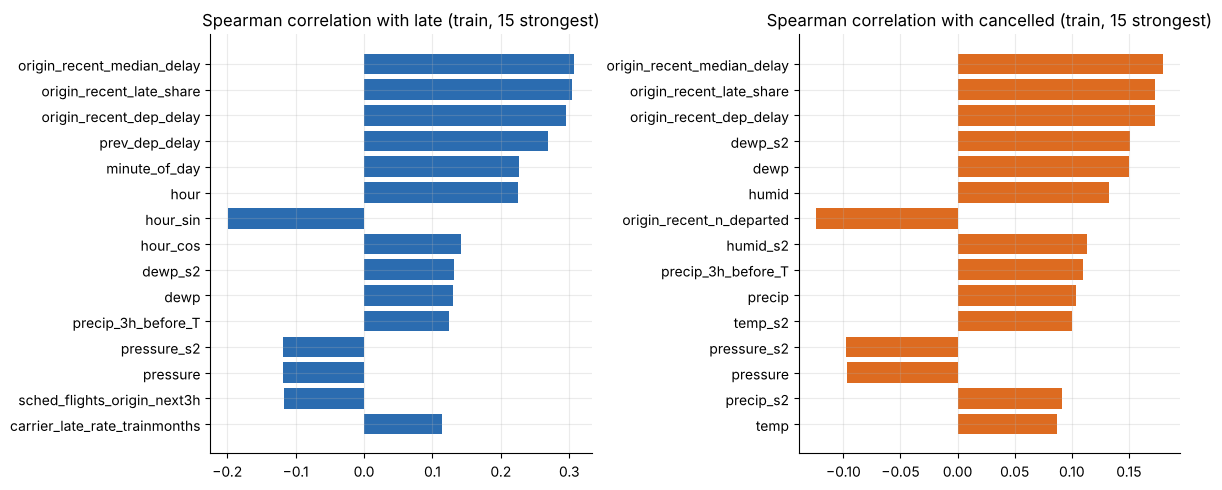

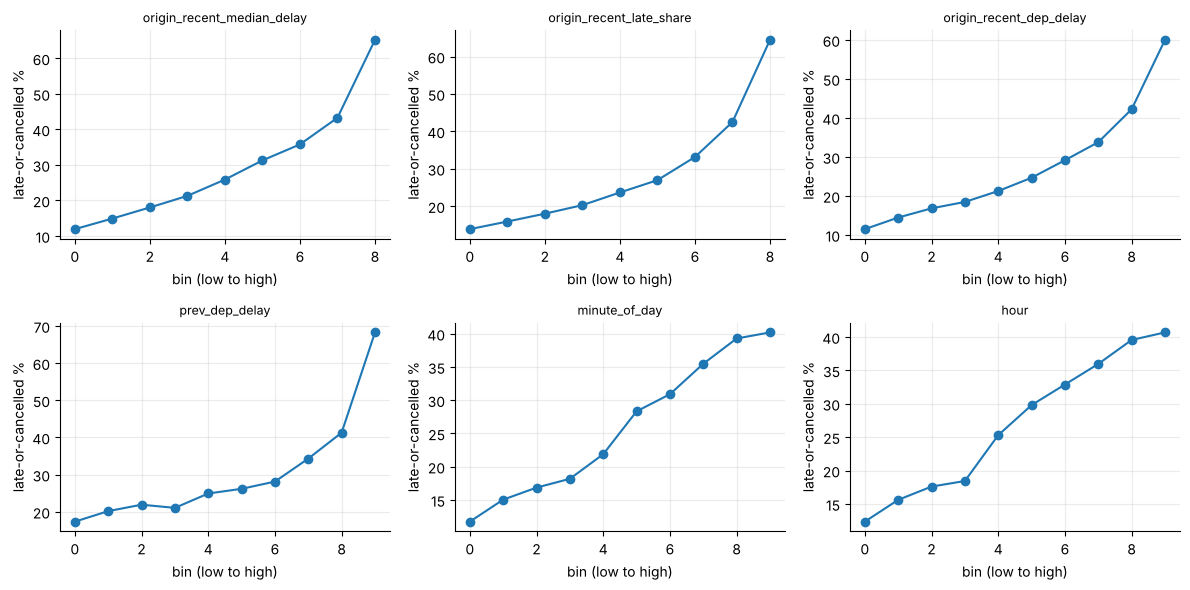

six strongest for late: ['origin_recent_median_delay', 'origin_recent_late_share', 'origin_recent_dep_delay', 'prev_dep_delay', 'minute_of_day', 'hour']


In [13]:
num = [c for c in FEATURES if pd.api.types.is_numeric_dtype(out[c])]
trn = out[out.part == "train"]
corr = pd.DataFrame({t: trn[num].corrwith(trn[t], method="spearman") for t in ["late", "cancelled"]})
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, t, col in zip(ax, ["late", "cancelled"], ["#2b6cb0", "#dd6b20"]):
    s = corr[t].reindex(corr[t].abs().sort_values().index).tail(15)
    a.barh(s.index, s.values, color=col); a.set_title(f"Spearman correlation with {t} (train, 15 strongest)")
plt.tight_layout(); plt.show()
top6 = corr.late.abs().sort_values(ascending=False).head(6).index.tolist()
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a, c in zip(ax.ravel(), top6):
    x = trn[c]
    b = pd.qcut(x, 10, duplicates="drop") if x.nunique() > 10 else x
    r = trn.groupby(b, observed=True).late.mean() * 100
    a.plot(range(len(r)), r.values, marker="o"); a.set_title(c, fontsize=9); a.set_ylabel("late-or-cancelled %"); a.set_xlabel("bin (low to high)")
plt.tight_layout(); plt.show()
print("six strongest for late:", top6)

## 11. Leak tests (automated)

Four tests. A failure stops the notebook.
- **(a) Forbidden columns.** No feature is an outcome column, a target, or a Task 1 flag.
- **(b) Slow loop.** For 1,000 random flights recompute `origin_recent_dep_delay` and `prev_dep_delay` with plain loops that check every event used, and require the same value as the fast version and that every event used happened at or before T.
- **(c) Delete the future.** Remove every flight scheduled after a cut-off time, recompute the airport-state and previous-flight features, and require that every remaining flight keeps **exactly the same values**. This is the strongest test of "nothing from the future".
- **(d) Strict weather.** The hour of every `_s2` observation starts at or before T.

In [14]:
FORBIDDEN = {"dep_time", "dep_delay", "arr_time", "arr_delay", "air_time", "late", "cancelled", "is_cancelled", "tail_missing", "tailnum", "flight",
             "tail_not_in_planes", "arrival_missing_but_departed", "arr_delay_missing_with_arr_time", "overnight_delay", "speed_flag", "year",
             "actual_dep_dt", "dep_time_fixed", "arr_time_fixed"}
assert not (set(FEATURES) & FORBIDDEN), set(FEATURES) & FORBIDDEN
assert not any(c.startswith(("dep_", "arr_")) for c in FEATURES)
print("(a) passed: no forbidden column among", len(FEATURES), "features")

# (b) slow loops
rng = np.random.default_rng(SEED)
pick = rng.choice(len(df), 1000, replace=False)
bad = 0; checked_events = 0
for i in pick:
    r = df.iloc[i]
    ev = df[(df.origin == r.origin) & df.dep_time.notna() & (df.actual_min > r.T_min - 120) & (df.actual_min <= r.T_min)]
    checked_events += len(ev)
    assert (ev.actual_min <= r.T_min).all()
    slow = ev.dep_delay.astype(float).mean() if len(ev) else np.nan
    fast = F.origin_recent_dep_delay.iloc[i]
    if not (np.isnan(slow) and np.isnan(fast)) and abs(slow - fast) > 1e-6: bad += 1
    if pd.notna(r.tailnum):
        pe = df[(df.tailnum == r.tailnum) & (df.date == r.date) & (df.sched_min < r.sched_min)].sort_values(["sched_min", "flight_row_id"])
        slow_p = np.nan
        if len(pe):
            last = pe.iloc[-1]
            if pd.notna(last.dep_delay) and last.actual_min <= r.T_min: slow_p = last.dep_delay
        fast_p = F.prev_dep_delay.iloc[i]
        if not (np.isnan(float(slow_p)) and np.isnan(fast_p)) and abs(float(slow_p) - fast_p) > 1e-6: bad += 1
    else:
        assert np.isnan(F.prev_dep_delay.iloc[i])
assert bad == 0, bad
print(f"(b) passed: 1,000 random flights, {checked_events:,} airport events checked, all at or before T, fast = slow")

(a) passed: no forbidden column among 51 features


(b) passed: 1,000 random flights, 38,761 airport events checked, all at or before T, fast = slow


In [15]:
# (c) delete the future
full_dyn = pd.concat([airport_state(df), prev_flight(df)], axis=1)
rng = np.random.default_rng(SEED)
cuts = np.sort(rng.choice(df.sched_min.to_numpy(), 6, replace=False))
for cut in cuts:
    keep = df.sched_min <= cut
    d2 = df[keep]
    dyn2 = pd.concat([airport_state(d2), prev_flight(d2)], axis=1)
    a, b = full_dyn.loc[d2.index].to_numpy(dtype=float), dyn2.to_numpy(dtype=float)
    same = np.isclose(a, b, equal_nan=True).all()
    assert same, f"values changed after deleting the future at minute {cut}"
    print(f"cut-off {pd.Timestamp('2023-01-01') + pd.Timedelta(minutes=float(cut))}: {keep.sum():,} flights kept, features of all of them identical")
print("(c) passed")
# (d) strict weather
assert (T_utc <= sched_utc - pd.Timedelta(hours=2)).all()
print("(d) passed: the hour of every strict-weather observation starts at or before T")
LEAK_TEST_PASSED = True

cut-off 2023-02-03 13:45:00: 38,856 flights kept, features of all of them identical


cut-off 2023-06-02 18:59:00: 188,513 flights kept, features of all of them identical


cut-off 2023-06-04 23:59:00: 191,095 flights kept, features of all of them identical


cut-off 2023-08-23 13:30:00: 284,981 flights kept, features of all of them identical


cut-off 2023-10-06 00:15:00: 336,965 flights kept, features of all of them identical


cut-off 2023-11-06 15:59:00: 373,709 flights kept, features of all of them identical
(c) passed
(d) passed: the hour of every strict-weather observation starts at or before T


In [16]:
table["known in advance"] = np.where(table.group == "Weather, scheduled hour", "yes, as a forecast stand-in (D5)", "yes") if LEAK_TEST_PASSED else "not checked"
table["known in advance"] = np.where(table.name.isin(["month", "week_of_year"]), "yes (calendar)", table["known in advance"])
pd.set_option("display.max_colwidth", 70)
display(table.drop(columns="missing values").groupby("group").head(2).head(5))
print(table["known in advance"].value_counts().to_dict())
out.to_parquet(PROC / "features.parquet", index=False)
table.to_parquet(PROC / "feature_table.parquet", index=False)
json.dump({"FEATURES": FEATURES, "META": META}, open(PROC / "feature_list.json", "w"))
print("saved features.parquet", out.shape, "and feature_table.parquet", table.shape)

,name,group,definition,why it could help,known in advance
0,dow,Calendar,Day of week of the scheduled departure (0 = Monday),Weekday patterns in traffic and delays,yes
1,month,Calendar,Scheduled month,"Seasons: summer storms, winter snow",yes (calendar)
9,distance,Flight,Route distance in miles,Long flights behave differently,yes
10,sched_block_min,Flight,Scheduled flying time in minutes (validated in section 2),"Longer schedule = more slack, other kind of flight",yes
11,carrier,Airline and route,Airline code,Reliability differs by airline (Task 2),yes


{'yes': 40, 'yes, as a forecast stand-in (D5)': 9, 'yes (calendar)': 2}


saved features.parquet (435352, 57) and feature_table.parquet (51, 6)


## 12. Ablation: do the plane features carry the missing-tail trap?

Plan check T2. A quick gradient boosting model is trained on January-June and scored on July-September (validation, never on the test part) with:
- all features,
- without the plane features,
- without `prev_dep_delay` and `prev_known_at_T`,
- without the airport-state features,
- and the **naive plane columns** (NaN where the tail is missing) instead of the D10 fill: the trap we are guarding against.

The target statistics are recomputed for this protocol (fit on January-June). PR-AUC is compared with the validation prevalence. If the D10 fill works, the plane features should add **no jump** for cancellation, while the naive version should jump.

In [17]:
sub = out[out.part == "train"].reset_index(drop=True)
sub["month"] = sub.month.astype(int)
fitm = (sub.month <= 6).to_numpy(); valm = sub.val.to_numpy()
tmp2 = pd.DataFrame({"carrier": sub.carrier, "route": sub.route, "late": sub.late, "month": sub.month})
sub["carrier_late_rate_trainmonths"] = oof_target_stat(tmp2, "carrier", "late", fitm).to_numpy()
sub["route_late_rate_trainmonths"] = oof_target_stat(tmp2, "route", "late", fitm).to_numpy()
sub_naive = sub.copy()
for c in ["plane_age", "seats", "engines", "manufacturer"]:
    sub_naive[c] = naive_plane[c].to_numpy()[TRAIN]

CATS = ["carrier", "origin", "dest", "dest_group", "manufacturer"]
PLANE = ["plane_age", "seats", "engines", "manufacturer"]
PREV = ["prev_dep_delay", "prev_known_at_T"]
STATE = ["origin_recent_dep_delay", "origin_recent_median_delay", "origin_recent_n_departed", "origin_recent_late_share"]
BASE = [c for c in FEATURES if c != "route"]

def run(data, cols, target):
    X = data[cols].copy()
    for c in CATS:
        if c in X: X[c] = X[c].astype("category").cat.codes
    m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_leaf_nodes=31, random_state=SEED,
                                       categorical_features=[c in CATS for c in cols])
    m.fit(X[fitm], data.loc[fitm, target])
    return average_precision_score(data.loc[valm, target], m.predict_proba(X[valm])[:, 1])

variants = {"all features (D10 fill)": (sub, BASE),
            "without plane features": (sub, [c for c in BASE if c not in PLANE]),
            "without prev_dep_delay": (sub, [c for c in BASE if c not in PREV]),
            "without airport-state features": (sub, [c for c in BASE if c not in STATE]),
            "NAIVE plane columns (NaN for missing tails)": (sub_naive, BASE)}
res = {}
for name, (data, cols) in variants.items():
    res[name] = {t: run(data, cols, t) for t in ["late", "cancelled"]}
abl = pd.DataFrame(res).T
abl.columns = ["PR-AUC late (val)", "PR-AUC cancelled (val)"]
prev_late, prev_canc = sub.loc[valm, "late"].mean(), sub.loc[valm, "cancelled"].mean()
print(f"validation prevalence: late {prev_late:.4f}, cancelled {prev_canc:.4f} (the dumb answer's PR-AUC)")
display(abl.round(4))

validation prevalence: late 0.2912, cancelled 0.0512 (the dumb answer's PR-AUC)


,PR-AUC late (val),PR-AUC cancelled (val)
all features (D10 fill),0.6211,0.2633
without plane features,0.6181,0.2514
without prev_dep_delay,0.6056,0.2505
without airport-state features,0.5176,0.1586
NAIVE plane columns (NaN for missing tails),0.6330,0.4576


In [18]:
j_d10 = abl.loc["all features (D10 fill)", "PR-AUC cancelled (val)"] - abl.loc["without plane features", "PR-AUC cancelled (val)"]
j_naive = abl.loc["NAIVE plane columns (NaN for missing tails)", "PR-AUC cancelled (val)"] - abl.loc["without plane features", "PR-AUC cancelled (val)"]
print(f"cancellation PR-AUC gain from plane features with the D10 fill: {j_d10:+.4f}")
print(f"cancellation PR-AUC gain from plane features left naive (NaN):  {j_naive:+.4f}")

cancellation PR-AUC gain from plane features with the D10 fill: +0.0119
cancellation PR-AUC gain from plane features left naive (NaN):  +0.2062


In [19]:
assert j_naive > 3 * max(abs(j_d10), 0.01), "the naive version should show the leak much more strongly than the D10 version"
assert abs(j_d10) < 0.03, "the D10 fill still leaks"
print("D10 works: the plane features add no jump, the naive version shows the trap.")

D10 works: the plane features add no jump, the naive version shows the trap.


**Reading the ablation.** (numbers above) The naive plane columns lift the cancellation score sharply, only because "tail missing" reveals which flights were cancelled. With the D10 fill the plane columns add (almost) nothing for cancellation, as they should: plane data does not tell the agency whether a flight will be cancelled. The airport-state and previous-flight rows show how much of the hidden information helps `late`; Task 6 re-measures this on the tuned models.

## Summary

- `features.parquet` (435,352 rows): about 50 feature columns, the two targets, `part` and `val` labels. `feature_table.parquet`: name, group, definition, why, missing values, known in advance.
- The new columns come from five sources: calendar, flight and route, plane (D10 random same-airline aircraft), weather in two sets (scheduled-hour and strict) and what happened at the airport and with the plane before T.
- Airline G4 has no aircraft in planes.csv at all, so its filled aircraft are drawn from all airlines' aircraft (11,284 flights are filled in total).
- The four leak tests pass; the ablation shows the missing-tail trap is closed.
- `utils.oof_target_stat` is reused in Task 6 with the validation protocol. `features_weather_literal.parquet` supports the Task 6 comparison row.